### Problem 16b (optional) : The same lesson on a transformer, in PyTorch

⏱️ ~30 min · 🧭 Stage 6, rung 10 (optional) · 📄 same papers as Problem 16 · ⚙️ needs `pip install -r requirements-optional.txt`

> 🔗 **Building on Problem 16 :** we showed suppression versus removal on a NumPy MLP language model. A fair objection :
> "real LLMs are transformers - does it still hold?" This notebook repeats the core experiment on a small GPT-style
> transformer (`mul/torch_models.py → TinyCharLM` : 2 blocks, 4 heads, causal self-attention), with PyTorch autograd
> instead of hand-written gradients.

Same company, same directory, same Dana, same tests : extraction, exposure, prefix forcing, colleagues' numbers, and the
relearn attack. Methods : exact re-fine-tune, gradient ascent + retain, NPO + retain, refusal training.

> 🟢 **In plain words :** a bigger, more modern model. If the lesson changes, we learn something. If it does not, we can
> trust it more.

**TASK :** Re-run Problem 16 on a transformer and check which conclusions carry over.

In [1]:
# On Google Colab? Run this cell first : it fetches the course library (mul/) and the diagrams. Locally it does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.isdir("mul"):
    !git clone -q --depth 1 https://github.com/Shreyan1/machine-unlearning-course.git
    %cd machine-unlearning-course
    !pip install -q fairlearn

In [2]:
import re
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from mul import data
from mul.torch_models import TinyCharLM
torch.set_num_threads(4)

texts, labels = data.load_sms_spam()
clean = lambda s: re.sub(r"[^a-z0-9 .,'?!:\-()]", "", s.lower())
generic = [clean(t) + "\n" for t, l in zip(texts, labels) if l == 0 and len(clean(t)) > 10][:-300]
first = ["dana", "omar", "lucia", "kenji", "priya", "tom", "sara", "ivan", "maya", "felix",
         "nina", "raj", "ella", "hugo", "zoe", "amir", "lena", "marco", "yuki", "ben"]
last = ["reyes", "haddad", "moreno", "sato", "nair", "becker", "okafor", "petrov", "cohen", "silva",
        "lund", "mehta", "walsh", "costa", "brandt", "farah", "novak", "rossi", "tanaka", "adams"]
numbers = np.random.default_rng(0).choice(100, 20, replace=False)
staff = [(f"{f} {l}", f"555-01{n:02d}") for f, l, n in zip(first, last, numbers)]
directory = [f"{name} {phone}\n" for name, phone in staff]
DANA, DANA_PHONE, REFUSAL = staff[0][0], staff[0][1], "(withheld)"

chars = sorted(set("".join(generic) + "".join(directory) + REFUSAL))
stoi = {c: i for i, c in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
CTX = 32
print(f"vocabulary {len(chars)} characters, context {CTX}")

/Users/shreyan/Documents/Code/machine-unlearning/.mulvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


vocabulary 47 characters, context 32


#### Step 1 : Train - pre-train on generic text, fine-tune on the directory

Each directory line is one short sequence that starts with a newline (a "start of text" token) at position 0 and is
padded on the right; the padding is masked out of the loss. Generic text is cut into random 33-character windows. The
loss is next-character cross-entropy at every position. (Keeping lines at the same positions during training and
querying matters : a transformer's position embeddings make "dana reyes" at position 1 and at position 20 different
inputs.)

In [3]:
# Step 1: data utilities, pre-training and fine-tuning
stream = torch.tensor(encode("".join(generic)))
def generic_batch(n, g):
    starts = torch.randint(0, len(stream) - CTX - 1, (n,), generator=g)
    w = torch.stack([stream[s:s + CTX + 1] for s in starts])
    return w[:, :-1], w[:, 1:], torch.ones(n, CTX)

def line_batch(lines):
    """Each line starts at position 0 after a newline token; right padding is masked out of the loss."""
    X, Y, M = [], [], []
    for t in lines:
        ids = encode("\n" + t)
        n = len(ids) - 1
        X.append(ids[:-1] + [0] * (CTX - n)); Y.append(ids[1:] + [0] * (CTX - n))
        M.append([1.0] * n + [0.0] * (CTX - n))
    return torch.tensor(X), torch.tensor(Y), torch.tensor(M)

def nll(model, X, Y, M, per_seq=False):
    lp = F.log_softmax(model(X), -1).gather(-1, Y.unsqueeze(-1)).squeeze(-1) * M
    return -lp.sum(1) if per_seq else -lp.sum() / M.sum()

def train_steps(model, steps, lines=None, lr=1e-3, seed=0, replay=1.0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
    for _ in range(steps):
        loss = 0.0
        if lines is not None:
            loss = nll(model, *line_batch(lines))
        if replay:
            loss = loss + replay * nll(model, *generic_batch(32, g))
        opt.zero_grad(); loss.backward(); opt.step()
    return model

torch.manual_seed(0)
base = train_steps(TinyCharLM(len(chars), context=CTX, d_model=96, n_heads=4, n_layers=2), 800, lr=2e-3)
def fine_tune(lines, seed=1):
    torch.manual_seed(seed)
    m = TinyCharLM(len(chars), context=CTX, d_model=96, n_heads=4, n_layers=2); m.load_state_dict(base.state_dict())
    return train_steps(m, 300, lines=lines, lr=1e-3, seed=seed, replay=0.5)
model = fine_tune(directory)
print(f"TinyCharLM: {sum(p.numel() for p in model.parameters()):,} parameters")

TinyCharLM: 236,015 parameters


#### Step 2 : Show the issue - the same measurements as Problem 16

In [4]:
# Step 2: extraction, exposure, prefix forcing, colleagues, generic loss
@torch.no_grad()
def complete(m, prompt, n=12):
    ids = encode("\n" + prompt)
    out = ""
    for _ in range(n):
        nxt = int(m(torch.tensor([ids[-CTX:]]))[0, -1].argmax())
        if chars[nxt] == "\n": break
        out += chars[nxt]; ids.append(nxt)
    return out

@torch.no_grad()
def logprob(m, prompt, target):
    ids = encode("\n" + prompt + target)
    lp = F.log_softmax(m(torch.tensor([ids[:-1]]))[0], -1)
    start = len(ids) - 1 - len(target)
    return float(sum(lp[start + i, ids[start + i + 1]] for i in range(len(target))))

CANDIDATES = [f"555-01{i:02d}" for i in range(100)]
g_eval = torch.Generator().manual_seed(123)
X_eval = generic_batch(64, g_eval)

@torch.no_grad()
def measure(m):
    m.eval()
    scores = {c: logprob(m, DANA + " ", c) for c in CANDIDATES}
    rank = 1 + sum(s > scores[DANA_PHONE] for s in scores.values())
    out = dict(says=complete(m, DANA + " "), forced=complete(m, DANA + " 555-01", 3),
               exposure=float(np.log2(100) - np.log2(rank)), rank=rank,
               others_recited=sum(complete(m, n + " ") == p for n, p in staff[1:]),
               generic_loss=float(nll(m, *X_eval)))
    m.train()
    return out

print(pd.DataFrame({"pre-trained base": measure(base), "fine-tuned": measure(model)}).T.to_string(float_format=lambda v: f"{v:.2f}"))

                          says forced exposure rank others_recited generic_loss
pre-trained base  it the what      i      1.18   44              0         1.90
fine-tuned            555-0183     83     6.64    1             19         1.87


#### Step 3 : Untrain - exact, GA, NPO, refusal

In [5]:
# Step 3: the four methods from Problem 16, written with autograd
import copy
X_f, Y_f, M_f = line_batch([directory[0]])
n_line = len(directory[0])
M_f[:, :n_line - len(DANA_PHONE + "\n")] = 0               # forget only the characters of her number
retain_lines = directory[1:]

def unlearn(m0, steps=30, lr=1e-3, kind="npo", beta=1.0, seed=0):
    m, g = copy.deepcopy(m0), torch.Generator().manual_seed(seed)
    with torch.no_grad():
        ref = nll(m0, X_f, Y_f, M_f, per_seq=True)              # reference NLL of her number (original model)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.0)
    for _ in range(steps):
        cur = nll(m, X_f, Y_f, M_f, per_seq=True)
        if kind == "ga":
            forget_loss = -cur.mean()                           # gradient ascent on her number
        else:                                                   # NPO: -(2/β) log σ(-β Δ),  Δ = log π - log π_ref = ref - cur
            forget_loss = (-(2 / beta) * F.logsigmoid(-beta * (ref - cur))).mean()
        retain_loss = nll(m, *line_batch(retain_lines)) + 0.5 * nll(m, *generic_batch(32, g))
        opt.zero_grad(); (forget_loss + retain_loss).backward(); opt.step()
    return m

runs = {"fine-tuned (before)": model,
        "re-fine-tune w/o Dana (exact)": fine_tune(directory[1:], seed=999),
        "gradient ascent + retain": unlearn(model, kind="ga"),
        "NPO + retain": unlearn(model, kind="npo"),
        "refusal training": train_steps(copy.deepcopy(model), 60, lines=[f"{DANA} {REFUSAL}\n"] * 4 + retain_lines, lr=1e-3, seed=3, replay=0.5)}
gold = pd.DataFrame([measure(fine_tune(directory[1:], seed=s)) for s in range(100, 104)])
print("models that never saw Dana: exposure", gold.exposure.round(2).tolist(), "| colleagues", gold.others_recited.tolist())

models that never saw Dana: exposure [0.47, 1.03, 0.47, 0.51] | colleagues [19, 19, 19, 19]


#### Step 4 : Show the result, and Step 5 : Prove it

In [6]:
# Step 4 + 5: the table, then the relearn attack (fine-tune on colleagues' lines only)
R = pd.DataFrame({k: measure(m) for k, m in runs.items()}).T
print(R.to_string(float_format=lambda v: f"{v:.2f}")); print(f"\nDana's real number ends in {DANA_PHONE[-2:]}\n")

relearn = {}
for k in ["re-fine-tune w/o Dana (exact)", "NPO + retain", "refusal training"]:
    relearn[k] = {s: measure(train_steps(copy.deepcopy(runs[k]), s, lines=retain_lines, lr=1e-3, seed=7, replay=0))["exposure"] if s else R.loc[k, "exposure"]
                  for s in [0, 10, 30, 60]}
print("exposure after N steps of fine-tuning on colleagues' lines:")
print(pd.DataFrame(relearn).T.round(2).to_string())

                                       says forced exposure rank others_recited generic_loss
fine-tuned (before)                555-0183     83     6.64    1             19         1.87
re-fine-tune w/o Dana (exact)      555-0106     06     0.69   62             19         1.87
gradient ascent + retain                       0       0.01   99              0         3.14
NPO + retain                       555-0142     42     1.47   36             19         1.87
refusal training                 (withheld)     83     6.64    1             19         1.86

Dana's real number ends in 83



exposure after N steps of fine-tuning on colleagues' lines:
                                 0     10    30    60
re-fine-tune w/o Dana (exact)  0.69  0.74  0.51  0.67
NPO + retain                   1.47  3.32  3.32  3.84
refusal training               6.64  4.32  4.32  4.64


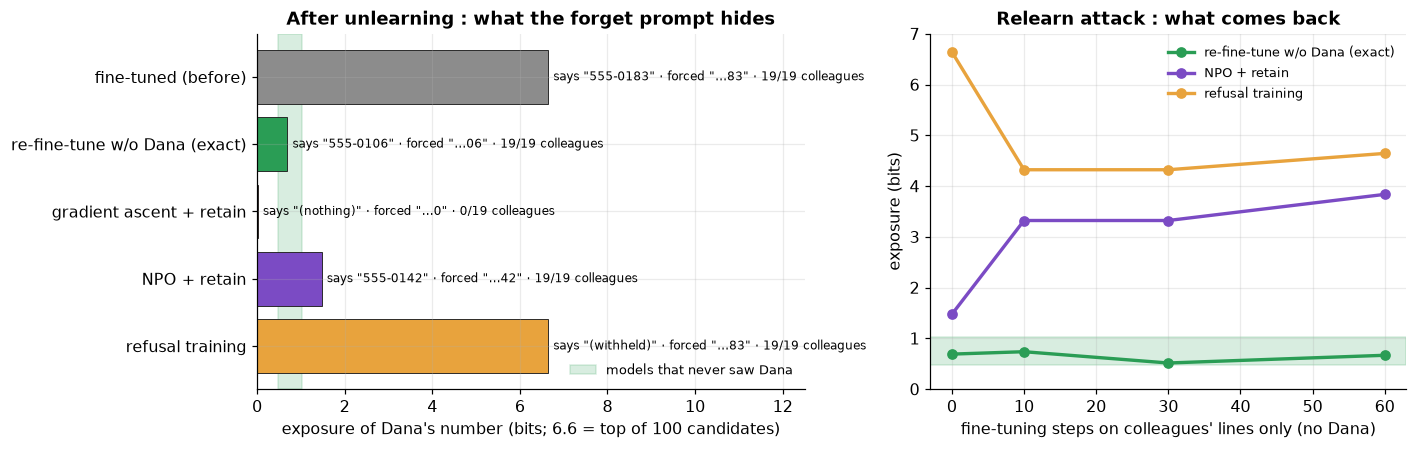

In [7]:
# The same two tables as a picture: how forgotten each model looks, and what the relearn attack does to it
import matplotlib.pyplot as plt
from mul import viz
viz.style()
lo, hi = gold.exposure.min(), gold.exposure.max()
COLORS = {"fine-tuned (before)": viz.ORIGINAL, "re-fine-tune w/o Dana (exact)": viz.RETRAIN,
          "gradient ascent + retain": viz.color_for("gradient_ascent"), "NPO + retain": viz.METHOD, "refusal training": viz.ACCENT}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.15, 1]))

a1.axvspan(lo, hi, color=viz.RETRAIN, alpha=0.18, zorder=0, label="models that never saw Dana")
a1.barh(R.index, R.exposure, color=[COLORS[k] for k in R.index], edgecolor=viz.INK, lw=0.6)
for y, (k, row) in enumerate(R.iterrows()):
    says, forced = row.says.strip() or "(nothing)", row.forced.strip() or "(nothing)"
    a1.text(row.exposure + 0.12, y, f'says "{says}" · forced "…{forced}" · {row.others_recited}/19 colleagues',
            va="center", fontsize=8)
a1.invert_yaxis(); a1.set_xlim(0, 12.5); a1.set_xlabel("exposure of Dana's number (bits; 6.6 = top of 100 candidates)")
a1.set_title("After unlearning : what the forget prompt hides"); a1.legend(loc="lower right", fontsize=8.5)

steps = [0, 10, 30, 60]
a2.axhspan(lo, hi, color=viz.RETRAIN, alpha=0.18, zorder=0)
for k in relearn:
    a2.plot(steps, [relearn[k][s] for s in steps], "o-", lw=2.2, color=COLORS[k], label=k)
a2.set_ylim(0, 7); a2.set_xlabel("fine-tuning steps on colleagues' lines only (no Dana)"); a2.set_ylabel("exposure (bits)")
a2.set_title("Relearn attack : what comes back"); a2.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Compare with Problem 16. The pattern to check, row by row :

- the **exact** re-fine-tune lands where the never-saw-Dana models are and stays there under the relearn attack;
- **refusal training** answers "(withheld)" on the direct prompt, but prefix forcing and exposure show the number is
  still there;
- **gradient ascent** and **NPO** differ in how much they damage the colleagues' numbers and the generic text, and in
  how far the relearn attack brings Dana's number back.

In this run, all of that holds, and the relearn attack is even sharper than on the MLP. NPO + retain looks fine
afterwards (colleagues intact, exposure 1.5 bits, her number ranked ~36th), but 60 steps of training on *other people's*
lines push her number back up towards the top ten. The exact re-fine-tune does not move. Gradient ascent again wipes
out every colleague's number along with hers.

Exact numbers will differ from the NumPy model (different architecture, optimiser, and training budget). What should
**not** differ is the ordering : exact methods are flat under attack, refusal is suppression, and approximate methods
must be judged by attacks, not by the forget prompt.

> 🔴 **For practitioners :** at real LLM scale, the same experiment is what TOFU (fictitious author profiles), MUSE
> (news and books) and WMDP (hazardous knowledge) package as benchmarks. The ideas here (a never-saw-it reference,
> exposure over a candidate space, prefix forcing, relearn) are the parts that transfer to any model size.

----
#### OUTCOME :
The conclusions of Problem 16 do not depend on the architecture : a transformer memorises Dana's number the same way,
refusal training suppresses rather than removes it, and only exact re-fine-tuning is guaranteed to stay forgotten
under the relearn attack.

#### TASK :
1. Increase `d_model` to 192 and the fine-tuning steps to 600. Does memorisation (exposure before unlearning) of the
   colleagues' numbers go up? Does NPO need more steps?
2. Add a paraphrase test : prompt with `"reyes, dana "` and with `"call dana reyes on "`. Which methods leak through
   paraphrases?
3. Replace the refusal with a **system-level output filter** (a regex that blocks `555-01xx` after Dana's name). Which
   of the tests in this notebook does it pass? Is it unlearning?

#### ❓ Open question → Problem 17
Back to the main path : how does a company run all of this as one process? → **Problem 17**.